<a href="https://colab.research.google.com/github/Mohtasir/Hand_Written_Recognition/blob/main/Hand_Written_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="white")

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


In [ ]:
from google.colab import drive

drive.mount("/content/drive")   # allow access in the pop-up

SAVE_DIR = "/content/drive/MyDrive/CodeAlpha_HandwrittenCharacterRecognition"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving everything to:", SAVE_DIR)

def save_fig(name):
    """Call just before plt.show() to also save the plot to Drive."""
    plt.savefig(f"{SAVE_DIR}/{name}.png", dpi=150, bbox_inches="tight")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving everything to: /content/drive/MyDrive/CodeAlpha_HandwrittenCharacterRecognition


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train_full.shape)
print("Test images    :", x_test.shape)
print("Pixel range    :", x_train_full.min(), "to", x_train_full.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Test images    : (10000, 28, 28)
Pixel range    : 0 to 255


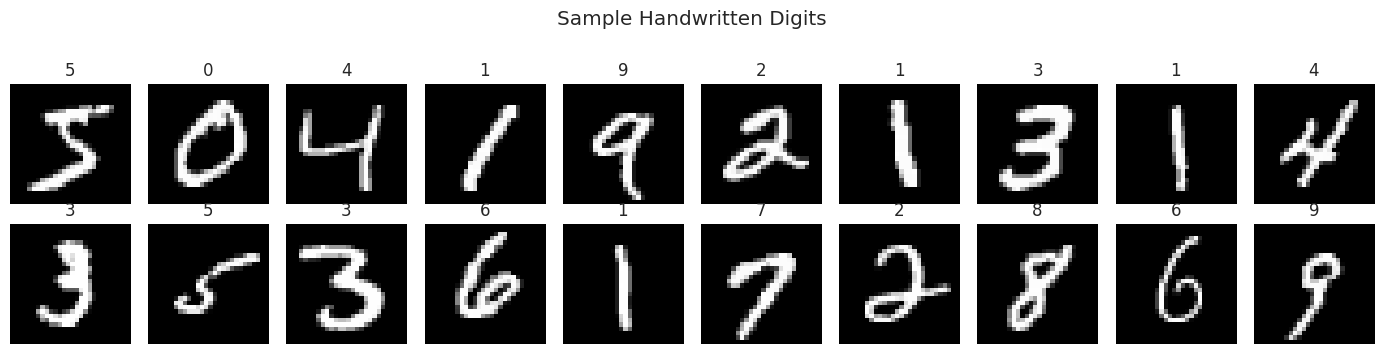

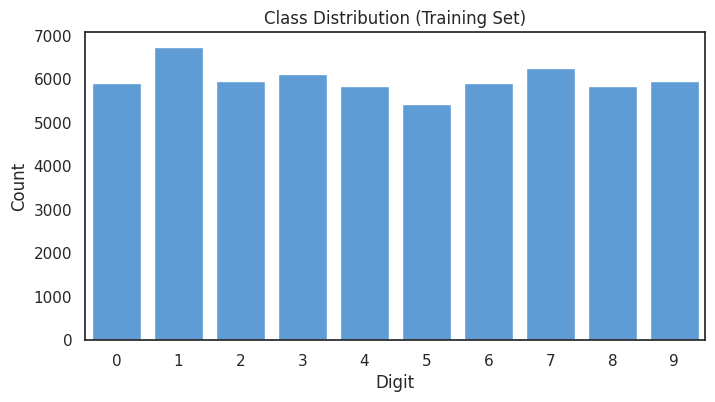

In [ ]:
# Sample images
fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train_full[i], cmap="gray")
    ax.set_title(int(y_train_full[i]))
    ax.axis("off")
plt.suptitle("Sample Handwritten Digits", y=1.02)
plt.tight_layout()
save_fig("00_samples")
plt.show()

# Class distribution
plt.figure(figsize=(8, 4))
sns.countplot(x=y_train_full, color="#4c9be8")
plt.title("Class Distribution (Training Set)")
plt.xlabel("Digit")
plt.ylabel("Count")
save_fig("01_class_distribution")
plt.show()

In [ ]:
# Normalize pixels to 0-1 and add a channel dimension: (N, 28, 28, 1)
x_train_full = (x_train_full.astype("float32") / 255.0)[..., np.newaxis]
x_test = (x_test.astype("float32") / 255.0)[..., np.newaxis]

# Hold out 10% of the training data for validation
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=SEED)

print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)

Train: (54000, 28, 28, 1) | Validation: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


In [ ]:
def build_cnn(num_classes, name="cnn"):
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        # Data augmentation (active only during training)
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomZoom(0.08),

        # Block 1
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        # Classifier
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ], name=name)

    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_cnn(10, name="mnist_cnn")
model.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,714 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
MODEL_PATH = f"{SAVE_DIR}/mnist_cnn_model.keras"
HISTORY_PATH = f"{SAVE_DIR}/training_history.csv"

if os.path.exists(MODEL_PATH) and os.path.exists(HISTORY_PATH):
    # Trained before, so load it. No retraining needed.
    model = keras.models.load_model(MODEL_PATH)
    hist = pd.read_csv(HISTORY_PATH)
    print("Loaded saved model from Drive. Skipping training.")
else:
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=2, min_lr=1e-5, verbose=1),
        # Saves the best model to Drive after every improved epoch
        keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy",
                                        save_best_only=True, verbose=1),
    ]

    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=30,
        batch_size=128,
        callbacks=callbacks,
        verbose=1,
    )

    hist = pd.DataFrame(history.history)
    hist.to_csv(HISTORY_PATH, index=False)
    model.save(MODEL_PATH)
    print("Model and training history saved to Drive.")

Loaded saved model from Drive. Skipping training.


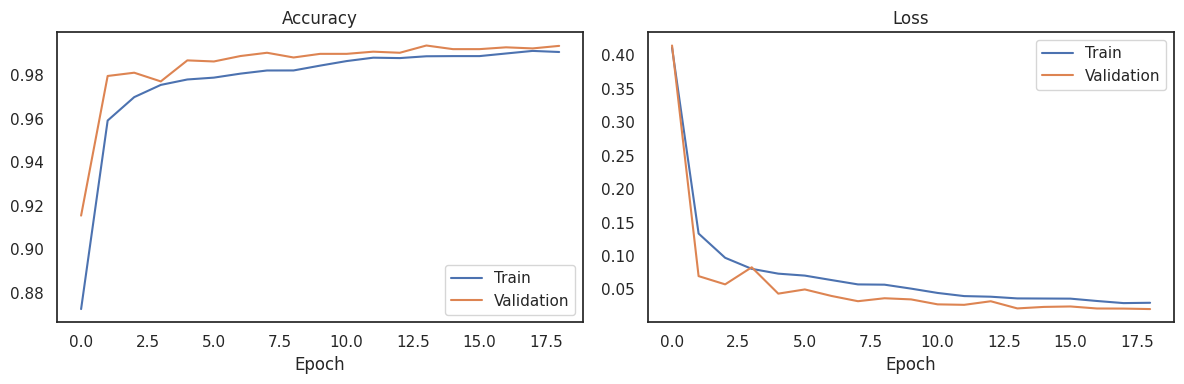

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist["accuracy"], label="Train")
axes[0].plot(hist["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(hist["loss"], label="Train")
axes[1].plot(hist["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
save_fig("02_training_curves")
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4%}")
print(f"Test loss    : {test_loss:.4f}")

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

Test accuracy: 99.3500%
Test loss    : 0.0198


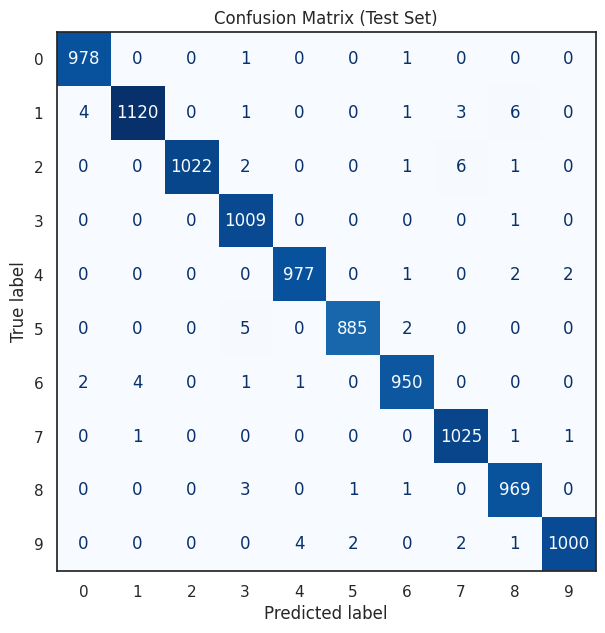

              precision    recall  f1-score   support

           0     0.9939    0.9980    0.9959       980
           1     0.9956    0.9868    0.9912      1135
           2     1.0000    0.9903    0.9951      1032
           3     0.9873    0.9990    0.9931      1010
           4     0.9949    0.9949    0.9949       982
           5     0.9966    0.9922    0.9944       892
           6     0.9927    0.9916    0.9922       958
           7     0.9894    0.9971    0.9932      1028
           8     0.9878    0.9949    0.9913       974
           9     0.9970    0.9911    0.9940      1009

    accuracy                         0.9935     10000
   macro avg     0.9935    0.9936    0.9935     10000
weighted avg     0.9935    0.9935    0.9935     10000



In [ ]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (Test Set)")
save_fig("03_confusion_matrix")
plt.show()

print(classification_report(y_test, y_pred, digits=4))

Misclassified: 65 out of 10000


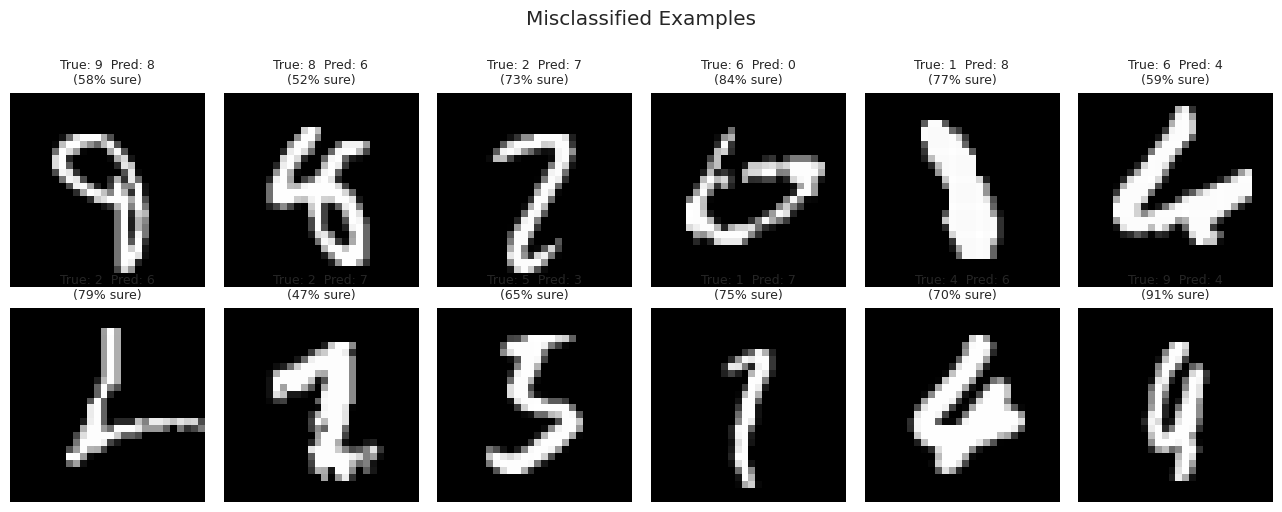

In [ ]:
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} out of {len(y_test)}")

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, idx in zip(axes.ravel(), wrong[:12]):
    ax.imshow(x_test[idx].squeeze(), cmap="gray")
    ax.set_title(f"True: {y_test[idx]}  Pred: {y_pred[idx]}\n({y_prob[idx].max():.0%} sure)", fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified Examples", y=1.02)
plt.tight_layout()
save_fig("04_misclassified")
plt.show()

In [ ]:
from PIL import Image, ImageOps

def predict_image(path, show=True):
    """Predict a digit from your own image (a photo or drawing of one digit)."""
    img = Image.open(path).convert("L")
    img = ImageOps.autocontrast(img)
    if np.array(img).mean() > 127:      # MNIST digits are white on black
        img = ImageOps.invert(img)
    img = img.resize((28, 28))
    arr = np.array(img).astype("float32") / 255.0
    probs = model.predict(arr[np.newaxis, ..., np.newaxis], verbose=0)[0]
    digit = int(np.argmax(probs))
    if show:
        plt.imshow(arr, cmap="gray")
        plt.title(f"Prediction: {digit} ({probs[digit]:.1%})")
        plt.axis("off")
        plt.show()
    return digit, probs

# Example (upload a file in Colab first, then use its name):
# predict_image("my_digit.png")

In [ ]:
with open(f"{SAVE_DIR}/results.txt", "w") as f:
    f.write(f"Test accuracy: {test_acc:.4%}\n")
    f.write(f"Test loss: {test_loss:.4f}\n\n")
    f.write(classification_report(y_test, y_pred, digits=4))

print("Files in your Drive folder:")
for name in sorted(os.listdir(SAVE_DIR)):
    print(" -", name)

Files in your Drive folder:
 - 00_samples.png
 - 01_class_distribution.png
 - 02_training_curves.png
 - 03_confusion_matrix.png
 - 04_misclassified.png
 - mnist_cnn_model.keras
 - results.txt
 - training_history.csv
